# 딥러닝및실습 Homework #2 

- **wandb 프로젝트**: https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic
- **Kaggle 대회**: https://www.kaggle.com/competitions/titanic

In [1]:
import os
import sys
import io
import contextlib
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
import wandb
import matplotlib.pyplot as plt

%matplotlib inline

#노트북 위치에서 두 단계 위인 link_dl 폴더를 BASE_PATH로 설정
CURRENT_FILE_PATH = os.path.abspath("")
BASE_PATH = os.path.abspath(os.path.join(CURRENT_FILE_PATH, "..", ".."))
sys.path.append(BASE_PATH)

#최적 모델을 저장할 폴더
CHECKPOINT_FILE_PATH = os.path.join(CURRENT_FILE_PATH, "checkpoints")

from _03_homeworks.homework_2.titanic_dataset import get_preprocessed_dataset
from _01_code._99_common_utils.early_stopping import EarlyStopping

#wandb에 노트북 이름 기록
os.environ["WANDB_NOTEBOOK_NAME"] = "hw2.ipynb"

#실험 재현을 위한 시드 / 데이터 분할과 가중치 초기화를 고정함
SEED = 42

#그래프 색상 / 학습 : 파랑, 검증 : 주황
COLOR_TRAIN = "#2a78d6"
COLOR_VALID = "#eb6834"

print("BASE_PATH:", BASE_PATH)
print("python :", sys.version.split()[0])
print("torch  :", torch.__version__)
print("pandas :", pd.__version__)
print("wandb  :", wandb.__version__)

BASE_PATH: C:\University\Grade_3\3-2\DeepLearningClass\git\link_dl
python : 3.12.6
torch  : 2.14.0+cpu
pandas : 3.0.5
wandb  : 0.30.0


### 원본 데이터

In [2]:
train_df = pd.read_csv(os.path.join(CURRENT_FILE_PATH, "train.csv"))
test_df = pd.read_csv(os.path.join(CURRENT_FILE_PATH, "test.csv"))

print("train.csv:", train_df.shape, "| test.csv:", test_df.shape)
display(train_df.head())

#학습 + 테스트 데이터 전체의 결측치 개수 → 전처리에서 채워야 할 컬럼 확인
all_raw_df = pd.concat([train_df, test_df], sort=False)
print("[결측치 개수 (train + test)]")
print(all_raw_df.drop(columns=["Survived"]).isnull().sum().to_string())

#클래스 불균형 확인 / 사망이 약 62%로 더 많음
print("\n[train.csv 생존 비율]")
print(train_df["Survived"].value_counts(normalize=True).round(4).to_string())

train.csv: (891, 12) | test.csv: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


[결측치 개수 (train + test)]
PassengerId       0
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2

[train.csv 생존 비율]
Survived
0    0.6162
1    0.3838


In [3]:
import inspect
from _03_homeworks.homework_2 import titanic_dataset

#pandas 3.0에 맞게 수정한 전처리 함수 출력
#수정 1, 2 : fillna(inplace=True)는 pandas 3.0부터 원본에 반영이 안 돼서 alone, Embarked에 결측치가 남음 → 결과를 다시 대입하도록 수정
#수정 3 : 문자열 컬럼 dtype이 object에서 str로 바뀌어서 LabelEncoder가 적용 안 됨 → select_dtypes로 object, str 둘 다 선택하도록 수정
for fn in [titanic_dataset.get_preprocessed_dataset_4,
           titanic_dataset.get_preprocessed_dataset_5,
           titanic_dataset.get_preprocessed_dataset_6]:
    print(inspect.getsource(fn))

def get_preprocessed_dataset_4(all_df):
    # 가족수(family_num) 컬럼 새롭게 추가
    all_df["family_num"] = all_df["Parch"] + all_df["SibSp"]

    # 혼자탑승(alone) 컬럼 새롭게 추가
    all_df.loc[all_df["family_num"] == 0, "alone"] = 1
    #pandas 3.0부터는 복사 후 쓰기 방식 때문에 inplace로 바꾸면 원본에 반영이 안 돼서 다시 대입함
    all_df["alone"] = all_df["alone"].fillna(0)

    # 학습에 불필요한 컬럼 제거
    all_df = all_df.drop(["PassengerId", "Name", "family_name", "name", "Ticket", "Cabin"], axis=1)

    return all_df

def get_preprocessed_dataset_5(all_df):
    # title 값 개수 줄이기
    all_df.loc[
    ~(
            (all_df["title"] == "Mr") |
            (all_df["title"] == "Miss") |
            (all_df["title"] == "Mrs") |
            (all_df["title"] == "Master")
    ),
    "title"
    ] = "other"
    #pandas 3.0부터는 복사 후 쓰기 방식 때문에 inplace로 바꾸면 원본에 반영이 안 돼서 다시 대입함
    all_df["Embarked"] = all_df["Embarked"].fillna("missing")

    return all_df

def get_preprocessed_dataset_6(all_df):
    # 카테고리 변수를 LabelEncoder를 사용하여 수치값으로 변경하기
    #pan

### 전처리 결과, DataLoader 확인

In [4]:
torch.manual_seed(SEED)
train_dataset, validation_dataset, test_dataset = get_preprocessed_dataset()

print("train_dataset: {0}, validation_dataset: {1}, test_dataset: {2}".format(
    len(train_dataset), len(validation_dataset), len(test_dataset)
))
print("#" * 50)

train_data_loader = DataLoader(dataset=train_dataset, batch_size=16, shuffle=True)
validation_data_loader = DataLoader(dataset=validation_dataset, batch_size=len(validation_dataset))
test_data_loader = DataLoader(dataset=test_dataset, batch_size=len(test_dataset))

print("[TRAIN]")
for idx, batch in enumerate(train_data_loader):
    #처음 2개와 마지막 배치만 출력
    if idx < 2 or idx == len(train_data_loader) - 1:
        print("{0} - {1}: {2}".format(idx, batch['input'].shape, batch['target'].shape))
    elif idx == 2:
        print("...")

print("[VALIDATION]")
for idx, batch in enumerate(validation_data_loader):
    print("{0} - {1}: {2}".format(idx, batch['input'].shape, batch['target'].shape))

print("[TEST]")
for idx, batch in enumerate(test_data_loader):
    print("{0} - {1}".format(idx, batch['input'].shape))

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'title', 'family_num', 'alone'],
      dtype='str')
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked  title  \
0       0.0       3    1  22.0      1      0   7.2500         2      2   
1       1.0       1    0  38.0      1      0  71.2833         0      3   
2       1.0       3    0  26.0      0      0   7.9250         2      1   
3       1.0       1    0  35.0      1      0  53.1000         2      3   
4       0.0       3    1  35.0      0      0   8.0500         2      2   
5       0.0       3    1  29.0      0      0   8.4583         1      2   
6       0.0       1    1  54.0      0      0  51.8625         2      2   
7       0.0       3    1   2.0      3      1  21.0750         2      0   
8       1.0       3    0  27.0      0      2  11.1333         2      3   
9       1.0       2    0  14.0      1      0  30.0708         0      3   

   family_num  alone  
0           1    0.0  

### [요구사항 1] 

In [5]:
#요구사항 2에서 비교할 활성화 함수
ACTIVATION_FUNCTIONS = {
    "sigmoid": nn.Sigmoid,
    "relu": nn.ReLU,
    "elu": nn.ELU,
    "leaky_relu": nn.LeakyReLU,
}


def get_data(run):
    #학습 713개 / 검증 178개 / 테스트 418개로 데이터셋 구성
    train_dataset, validation_dataset, test_dataset = get_preprocessed_dataset()

    train_data_loader = DataLoader(dataset=train_dataset, batch_size=run.config.batch_size, shuffle=True)
    validation_data_loader = DataLoader(dataset=validation_dataset, batch_size=len(validation_dataset))
    test_data_loader = DataLoader(dataset=test_dataset, batch_size=len(test_dataset))

    #정규화에 쓸 평균, 표준편차는 학습 데이터에서만 계산 → 검증, 테스트 데이터 정보가 학습에 섞이지 않게 함
    train_X = train_dataset.dataset.X[train_dataset.indices]
    feature_mean = train_X.mean(dim=0)
    feature_std = train_X.std(dim=0)

    return train_data_loader, validation_data_loader, test_data_loader, feature_mean, feature_std


class MyModel(nn.Module):
    def __init__(self, n_input, n_output, feature_mean, feature_std, run):
        super().__init__()

        #특성마다 값의 범위가 크게 달라서 표준화함
        #buffer로 등록하면 학습은 안 되지만 모델과 같이 저장돼서 테스트 데이터에도 같은 값이 적용됨
        self.register_buffer("feature_mean", feature_mean)
        self.register_buffer("feature_std", feature_std)

        activation = ACTIVATION_FUNCTIONS[run.config.activation]

        self.model = nn.Sequential(
            nn.Linear(n_input, run.config.n_hidden_unit_list[0]),
            activation(),
            nn.Linear(run.config.n_hidden_unit_list[0], run.config.n_hidden_unit_list[1]),
            activation(),
            #생존, 사망 2개 중 하나로 분류하므로 출력 뉴런 2개 / softmax는 CrossEntropyLoss 안에서 처리됨
            nn.Linear(run.config.n_hidden_unit_list[1], n_output),
        )

    def forward(self, x):
        x = (x - self.feature_mean) / self.feature_std
        x = self.model(x)
        return x


def get_model_and_optimizer(feature_mean, feature_std, run):
    my_model = MyModel(n_input=10, n_output=2, feature_mean=feature_mean, feature_std=feature_std, run=run)
    optimizer = optim.SGD(my_model.parameters(), lr=run.config.learning_rate)

    return my_model, optimizer

In [6]:
def training_loop(model, optimizer, train_data_loader, validation_data_loader, run, early_stopping=None, verbose=True):
    n_epochs = run.config.epochs
    loss_fn = nn.CrossEntropyLoss() #분류 문제라서 MSELoss 대신 CrossEntropyLoss 사용
    next_print_epoch = 100
    best_epoch = None
    history = {"epoch": [], "training_loss": [], "validation_loss": [], "validation_accuracy": []}

    for epoch in range(1, n_epochs + 1):
        #학습
        model.train()
        loss_train = 0.0
        num_trains = 0
        for train_batch in train_data_loader:
            input, target = train_batch['input'], train_batch['target']
            output_train = model(input)
            loss = loss_fn(output_train, target)
            loss_train += loss.item()
            num_trains += 1

            optimizer.zero_grad() #이전 배치의 기울기 초기화
            loss.backward() #역전파로 기울기 계산
            optimizer.step() #SGD로 가중치 갱신

        #검증
        model.eval()
        loss_validation = 0.0
        num_validations = 0
        num_corrects = 0
        num_samples = 0
        with torch.no_grad(): #검증할 때는 기울기 계산이 필요 없음
            for validation_batch in validation_data_loader:
                input, target = validation_batch['input'], validation_batch['target']
                output_validation = model(input)
                loss = loss_fn(output_validation, target)
                loss_validation += loss.item()
                num_validations += 1

                #출력값이 가장 큰 클래스를 예측값으로 써서 정확도 계산
                num_corrects += (output_validation.argmax(dim=1) == target).sum().item()
                num_samples += len(target)

        training_loss = loss_train / num_trains
        validation_loss = loss_validation / num_validations
        validation_accuracy = num_corrects / num_samples

        #wandb에 에폭별 기록 업로드
        run.log({
            "Epoch": epoch,
            "Training loss": training_loss,
            "Validation loss": validation_loss,
            "Validation accuracy": validation_accuracy,
        })
        history["epoch"].append(epoch)
        history["training_loss"].append(training_loss)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        if verbose and epoch >= next_print_epoch:
            print(
                f"Epoch {epoch}, "
                f"Training loss {training_loss:.4f}, "
                f"Validation loss {validation_loss:.4f}, "
                f"Validation accuracy {validation_accuracy:.4f}"
            )
            next_print_epoch += 100

        if early_stopping is not None:
            #검증 손실이 delta 이상 줄면 모델 저장, patience 동안 안 줄면 학습 중단
            message, early_stop = early_stopping.check_and_save(validation_loss, model)
            if message.startswith("V_loss decreased"):
                best_epoch = epoch
                run.summary["Best epoch"] = best_epoch
                run.summary["Best validation accuracy"] = validation_accuracy
            if early_stop:
                print(f"Epoch {epoch}, {message}")
                print(f"→ best epoch: {best_epoch}, best validation loss: {early_stopping.val_loss_min:.4f}")
                break

    return history


def run_experiment(activation, batch_size, learning_rate, epochs=1_000,
                   wandb_mode="disabled", group=None,
                   early_stop=False, early_stop_patience=50, early_stop_delta=0.00001, verbose=True):
    #데이터 분할과 가중치 초기화를 고정해서 하이퍼파라미터끼리 공정하게 비교할 수 있게 함
    torch.manual_seed(SEED)

    current_time_str = datetime.now().astimezone().strftime('%Y-%m-%d_%H-%M-%S')

    config = {
        'epochs': epochs,
        'batch_size': batch_size,
        'learning_rate': learning_rate,
        'activation': activation,
        'n_hidden_unit_list': [20, 20],
        'seed': SEED,
        'early_stop': early_stop,
        'early_stop_patience': early_stop_patience,
        'early_stop_delta': early_stop_delta,
    }

    with wandb.init(
        mode=wandb_mode,
        project="titanic",
        notes="Titanic survival classification",
        tags=["my_model", "titanic"],
        group=group,
        name=current_time_str,
        config=config
    ) as run:
        if verbose:
            print(run.config)

        #가로축은 에폭, 세로축은 학습 손실로 그래프 그리기
        run.define_metric("Training loss", step_metric="Epoch")
        #가로축은 에폭, 세로축은 검증 손실로 그래프 그리기 / 실험 요약에는 가장 낮았던 값 저장
        run.define_metric("Validation loss", step_metric="Epoch", summary="min")
        run.define_metric("Validation accuracy", step_metric="Epoch", summary="max")

        with contextlib.redirect_stdout(io.StringIO()):
            train_data_loader, validation_data_loader, test_data_loader, feature_mean, feature_std = get_data(run)

        my_model, optimizer = get_model_and_optimizer(feature_mean, feature_std, run)

        early_stopping = None
        if early_stop:
            os.makedirs(CHECKPOINT_FILE_PATH, exist_ok=True)
            early_stopping = EarlyStopping(
                patience=early_stop_patience,
                delta=early_stop_delta,
                project_name="titanic",
                checkpoint_file_path=CHECKPOINT_FILE_PATH,
                run_time_str=current_time_str
            )

        history = training_loop(
            model=my_model,
            optimizer=optimizer,
            train_data_loader=train_data_loader,
            validation_data_loader=validation_data_loader,
            run=run,
            early_stopping=early_stopping,
            verbose=verbose
        )

        if early_stopping is not None:
            #마지막 에폭 모델이 아니라 검증 손실이 가장 낮았던 에폭의 모델을 불러옴
            my_model.load_state_dict(torch.load(early_stopping.file_path))
            print(f"Loaded best checkpoint: {os.path.basename(early_stopping.file_path)}")

    return my_model, history, test_data_loader

In [7]:
model_base, history_base, _ = run_experiment(
    activation="relu", batch_size=32, learning_rate=1e-3,
    wandb_mode="online", group="requirement_1"
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\Mycom\_netrc.
wandb: Currently logged in as: seoi180011 (seoi180011-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run xlfqfyyl
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\University\Grade_3\3-2\DeepLearningClass\git\link_dl\_03_homeworks\homework_2\wandb\run-20261016_020739-xlfqfyyl
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run 2026-10-16_02-07-35
wandb:  View project at https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic
wandb:  View run at https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic/runs/xlfqfyyl


{'epochs': 1000, 'batch_size': 32, 'learning_rate': 0.001, 'activation': 'relu', 'n_hidden_unit_list': [20, 20], 'seed': 42, 'early_stop': False, 'early_stop_patience': 50, 'early_stop_delta': 1e-05}
Epoch 100, Training loss 0.6133, Validation loss 0.5875, Validation accuracy 0.7472
Epoch 200, Training loss 0.5300, Validation loss 0.4977, Validation accuracy 0.8202
Epoch 300, Training loss 0.4634, Validation loss 0.4203, Validation accuracy 0.8596
Epoch 400, Training loss 0.4499, Validation loss 0.3883, Validation accuracy 0.8708
Epoch 500, Training loss 0.4488, Validation loss 0.3757, Validation accuracy 0.8652
Epoch 600, Training loss 0.4203, Validation loss 0.3706, Validation accuracy 0.8652
Epoch 700, Training loss 0.4167, Validation loss 0.3665, Validation accuracy 0.8764
Epoch 800, Training loss 0.4174, Validation loss 0.3635, Validation accuracy 0.8764
Epoch 900, Training loss 0.4092, Validation loss 0.3616, Validation accuracy 0.8764


wandb: updating run metadata


Epoch 1000, Training loss 0.4065, Validation loss 0.3612, Validation accuracy 0.8876


wandb: uploading history steps 570-999, summary
wandb: 
wandb: Run history:
wandb:               Epoch ▁▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███
wandb:       Training loss █▇▇▅▅▅▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: Validation accuracy ▁▁▅▅▅▅▅▅▅▆▆▆▆▇▇█████████████████████████
wandb:     Validation loss █▇▇▆▆▆▆▄▄▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:         Epoch 1000
wandb: Training loss 0.40654
wandb: 
wandb:  View run 2026-10-16_02-07-35 at: https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic/runs/xlfqfyyl
wandb:  View project at: https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: .\wandb\run-20261016_020739-xlfqfyyl\logs


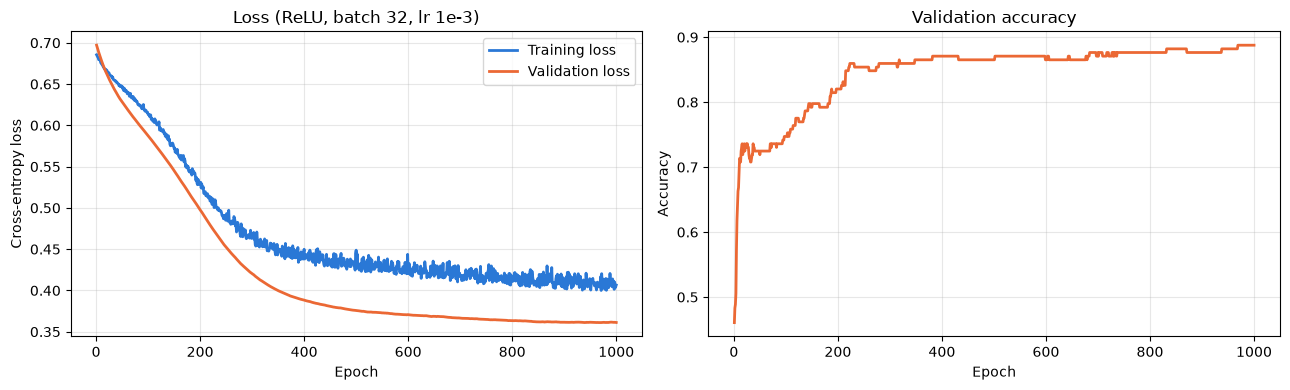

최종(1000 epoch) Training loss 0.4065, Validation loss 0.3612, Validation accuracy 0.8876


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_base["epoch"], history_base["training_loss"], color=COLOR_TRAIN, linewidth=2, label="Training loss")
axes[0].plot(history_base["epoch"], history_base["validation_loss"], color=COLOR_VALID, linewidth=2, label="Validation loss")
axes[0].set_title("Loss (ReLU, batch 32, lr 1e-3)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_base["epoch"], history_base["validation_accuracy"], color=COLOR_VALID, linewidth=2)
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"최종(1000 epoch) Training loss {history_base['training_loss'][-1]:.4f}, "
      f"Validation loss {history_base['validation_loss'][-1]:.4f}, "
      f"Validation accuracy {history_base['validation_accuracy'][-1]:.4f}")

### 요구사항 1 고찰

학습 손실과 검증 손실 모두 꾸준히 줄었고, 1000 에폭 동안 검증 손실이 다시 올라가는 과적합은 나타나지 않았음. 학습률 1e-3의 SGD는 수렴이 느려서 1000 에폭이 끝날 때까지도 손실이 조금씩 줄고 있었음. 검증 손실이 학습 손실보다 낮게 나왔는데, 학습 손실은 에폭 도중 가중치가 바뀌는 중에 계산한 평균이고 검증 손실은 에폭이 끝난 뒤 모델로 계산하기 때문으로 보임. 또 Fare처럼 값이 큰 특성이 학습을 지배하지 않도록 학습 데이터의 평균, 표준편차로 표준화해서 모든 특성이 비슷한 크기로 학습에 반영되게 함.

### [요구사항 2] 

In [9]:
ACTIVATIONS = ["sigmoid", "relu", "elu", "leaky_relu"]
BATCH_SIZES = [32, 64, 128]
LEARNING_RATES = [1e-2, 1e-3, 1e-4]

grid_results = []
grid_histories = {}

n = 0
for activation in ACTIVATIONS:
    for batch_size in BATCH_SIZES:
        for learning_rate in LEARNING_RATES:
            n += 1
            _, history, _ = run_experiment(
                activation=activation, batch_size=batch_size, learning_rate=learning_rate,
                wandb_mode="disabled", verbose=False
            )
            grid_histories[(activation, batch_size, learning_rate)] = history

            #검증 손실이 가장 낮았던 에폭 기준으로 성능 기록
            best_idx = int(np.argmin(history["validation_loss"]))
            grid_results.append({
                "activation": activation,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "min_validation_loss": history["validation_loss"][best_idx],
                "best_epoch": history["epoch"][best_idx],
                "validation_accuracy_at_best": history["validation_accuracy"][best_idx],
                "final_training_loss": history["training_loss"][-1],
                "final_validation_loss": history["validation_loss"][-1],
            })
            print(f"[{n:2d}/36] {activation:10s} batch {batch_size:3d} lr {learning_rate:<6g} → "
                  f"min V_loss {history['validation_loss'][best_idx]:.4f} (epoch {history['epoch'][best_idx]:4d}), "
                  f"V_acc {history['validation_accuracy'][best_idx]:.4f}")

[ 1/36] sigmoid    batch  32 lr 0.01   → min V_loss 0.3772 (epoch  892), V_acc 0.8652
[ 2/36] sigmoid    batch  32 lr 0.001  → min V_loss 0.6239 (epoch 1000), V_acc 0.7079
[ 3/36] sigmoid    batch  32 lr 0.0001 → min V_loss 0.6313 (epoch  971), V_acc 0.7079
[ 4/36] sigmoid    batch  64 lr 0.01   → min V_loss 0.3815 (epoch 1000), V_acc 0.8596
[ 5/36] sigmoid    batch  64 lr 0.001  → min V_loss 0.6281 (epoch  902), V_acc 0.7079
[ 6/36] sigmoid    batch  64 lr 0.0001 → min V_loss 0.6326 (epoch 1000), V_acc 0.7079
[ 7/36] sigmoid    batch 128 lr 0.01   → min V_loss 0.4929 (epoch  999), V_acc 0.7978
[ 8/36] sigmoid    batch 128 lr 0.001  → min V_loss 0.6305 (epoch  998), V_acc 0.7079
[ 9/36] sigmoid    batch 128 lr 0.0001 → min V_loss 0.6396 (epoch 1000), V_acc 0.7079
[10/36] relu       batch  32 lr 0.01   → min V_loss 0.3612 (epoch  111), V_acc 0.8764
[11/36] relu       batch  32 lr 0.001  → min V_loss 0.3610 (epoch  969), V_acc 0.8876
[12/36] relu       batch  32 lr 0.0001 → min V_loss 0.

In [10]:
grid_df = pd.DataFrame(grid_results).sort_values("min_validation_loss").reset_index(drop=True)
grid_df.index = grid_df.index + 1
grid_df.index.name = "rank"
grid_df.to_csv(os.path.join(CURRENT_FILE_PATH, "grid_search_results.csv"))

pd.set_option("display.max_rows", 40)
display(grid_df.style.format({
    "learning_rate": "{:g}",
    "min_validation_loss": "{:.4f}",
    "validation_accuracy_at_best": "{:.4f}",
    "final_training_loss": "{:.4f}",
    "final_validation_loss": "{:.4f}",
}))

best = grid_df.iloc[0]
print(f"\n★ 최적 조합: activation={best.activation}, batch_size={best.batch_size}, learning_rate={best.learning_rate:g}"
      f" → min Validation loss {best.min_validation_loss:.4f} (epoch {best.best_epoch}), "
      f"Validation accuracy {best.validation_accuracy_at_best:.4f}")

,activation,batch_size,learning_rate,min_validation_loss,best_epoch,validation_accuracy_at_best,final_training_loss,final_validation_loss
rank,,,,,,,,
1,leaky_relu,64,0.01,0.3597,222,0.8764,0.3486,0.3691
2,relu,64,0.01,0.3598,222,0.8764,0.3493,0.3694
3,leaky_relu,128,0.01,0.3607,401,0.8876,0.3725,0.3679
4,relu,128,0.01,0.3608,401,0.8876,0.3722,0.3682
5,leaky_relu,32,0.01,0.3609,111,0.8764,0.3188,0.3755
6,relu,32,0.001,0.3610,969,0.8876,0.4065,0.3612
7,leaky_relu,32,0.001,0.3611,969,0.8820,0.4069,0.3613
8,relu,32,0.01,0.3612,111,0.8764,0.3216,0.3709
9,elu,64,0.01,0.3647,511,0.8708,0.3814,0.3729



★ 최적 조합: activation=leaky_relu, batch_size=64, learning_rate=0.01 → min Validation loss 0.3597 (epoch 222), Validation accuracy 0.8764


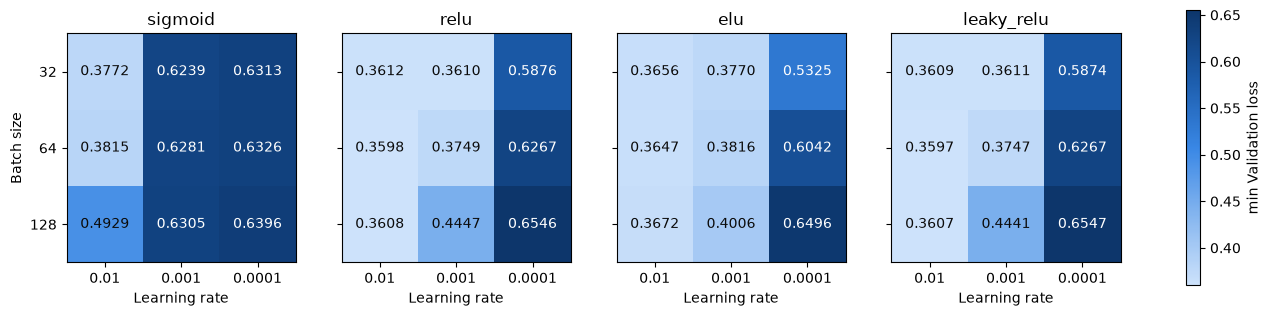

In [11]:
from matplotlib.colors import LinearSegmentedColormap

#파란색 진하기로 손실 크기 표시 / 연할수록 좋고 진할수록 나쁨
blue_ramp = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
vmin, vmax = grid_df["min_validation_loss"].min(), grid_df["min_validation_loss"].max()

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, activation in zip(axes, ACTIVATIONS):
    matrix = np.array([[grid_df[(grid_df.activation == activation) &
                                (grid_df.batch_size == b) &
                                (grid_df.learning_rate == lr)]["min_validation_loss"].item()
                        for lr in LEARNING_RATES] for b in BATCH_SIZES])
    im = ax.imshow(matrix, cmap=blue_ramp, vmin=vmin, vmax=vmax)
    for i in range(len(BATCH_SIZES)):
        for j in range(len(LEARNING_RATES)):
            value = matrix[i, j]
            text_color = "white" if (value - vmin) / (vmax - vmin) > 0.5 else "#0b0b0b"
            ax.text(j, i, f"{value:.4f}", ha="center", va="center", color=text_color, fontsize=10)
    ax.set_title(activation)
    ax.set_xticks(range(len(LEARNING_RATES)), [f"{lr:g}" for lr in LEARNING_RATES])
    ax.set_yticks(range(len(BATCH_SIZES)), BATCH_SIZES)
    ax.set_xlabel("Learning rate")
axes[0].set_ylabel("Batch size")
fig.colorbar(im, ax=axes, shrink=0.85, label="min Validation loss")
plt.show()

In [12]:
for column in ["activation", "batch_size", "learning_rate"]:
    summary = grid_df.groupby(column)["min_validation_loss"].agg(["mean", "min", "max"]).sort_values("mean")
    print(f"[{column}]")
    print(summary.round(4).to_string())
    print()

[activation]
              mean     min     max
activation                        
elu         0.4492  0.3647  0.6496
leaky_relu  0.4589  0.3597  0.6547
relu        0.4590  0.3598  0.6546
sigmoid     0.5597  0.3772  0.6396

[batch_size]
              mean     min     max
batch_size                        
32          0.4606  0.3609  0.6313
64          0.4763  0.3597  0.6326
128         0.5083  0.3607  0.6547

[learning_rate]
                 mean     min     max
learning_rate                        
0.0100         0.3760  0.3597  0.4929
0.0010         0.4502  0.3610  0.6305
0.0001         0.6190  0.5325  0.6547



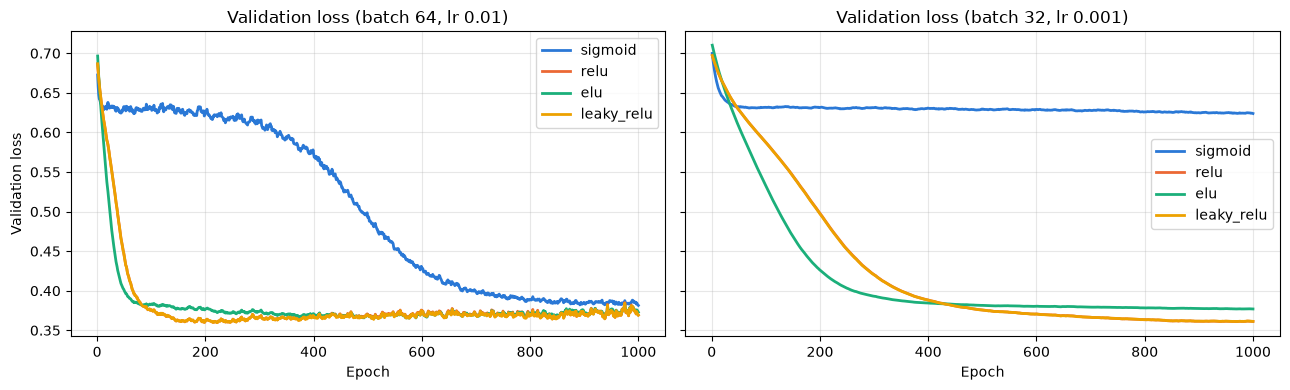

검증 데이터 사망자 비율: 0.7079 (126 / 178)
Sigmoid(batch 32, lr 1e-3)의 Validation accuracy 범위: 0.2921 ~ 0.7079


In [13]:
ACTIVATION_COLORS = {"sigmoid": "#2a78d6", "relu": "#eb6834", "elu": "#1baf7a", "leaky_relu": "#eda100"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (batch_size, learning_rate) in zip(axes, [(64, 1e-2), (32, 1e-3)]):
    for activation in ACTIVATIONS:
        h = grid_histories[(activation, batch_size, learning_rate)]
        ax.plot(h["epoch"], h["validation_loss"], color=ACTIVATION_COLORS[activation], linewidth=2, label=activation)
    ax.set_title(f"Validation loss (batch {batch_size}, lr {learning_rate:g})")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Validation loss")
plt.tight_layout()
plt.show()

#Sigmoid + 학습률 1e-3에서 정확도가 멈춰 있는 원인 확인 / 검증 데이터의 사망자 비율
validation_targets = next(iter(DataLoader(validation_dataset, batch_size=len(validation_dataset))))['target']
print(f"검증 데이터 사망자 비율: {(validation_targets == 0).float().mean():.4f} "
      f"({(validation_targets == 0).sum().item()} / {len(validation_targets)})")
print(f"Sigmoid(batch 32, lr 1e-3)의 Validation accuracy 범위: "
      f"{min(grid_histories[('sigmoid', 32, 1e-3)]['validation_accuracy']):.4f} ~ "
      f"{max(grid_histories[('sigmoid', 32, 1e-3)]['validation_accuracy']):.4f}")

### 요구사항 2 고찰

가장 성능이 좋은 조합 : Leaky ReLU, 배치 크기 64, 학습률 1e-2

활성화 함수

Sigmoid는 학습률 1e-3, 1e-4에서 검증 정확도가 0.7079에 거의 내내 머물렀음. 이 값은 검증 데이터의 사망자 비율과 같아서, 모델이 모든 승객을 사망으로만 예측하는 상태에 갇혔다는 뜻임. Sigmoid는 미분값이 최대 0.25라 층을 지날수록 기울기가 작아지는 기울기 소실이 생기고, 작은 학습률로는 이 상태를 벗어나지 못한 것으로 보임. 반면 학습률 1e-2에서는 한동안 정체하다가 결국 학습됐기 때문에, Sigmoid도 학습률과의 궁합이 중요하다는 걸 확인함. ReLU와 Leaky ReLU는 음수 쪽 기울기 차이가 0.01뿐이라 결과가 거의 같았고, ELU는 초반 수렴은 빨랐지만 최종 성능은 조금 낮았음.

배치 크기

학습률 1e-3에서는 32가, 1e-2에서는 64가 가장 좋았음. 배치 크기가 크면 에폭당 가중치 갱신 횟수가 줄어드는데, 학습률이 크면 이를 보완할 수 있기 때문임. 즉 배치 크기와 학습률은 서로 영향을 주는 하이퍼파라미터임.

학습률

결과에 가장 큰 영향을 줬음. 상위 5개가 모두 1e-2였고, 1e-4는 1000 에폭 안에 수렴하지 못함. 다만 1e-2는 최저점에 빨리 도달한 뒤 과적합이 나타나서, 요구사항 3에서 EarlyStopping으로 해결함.

조합 전체를 비교한 이유

하이퍼파라미터를 하나씩 따로 골랐다면 36개 중 6위 조합을 선택했을 것임. 하이퍼파라미터끼리 서로 영향을 주기 때문에 조합 전체를 비교해야 실제 최적 조합을 찾을 수 있음.

### [요구사항 3] 

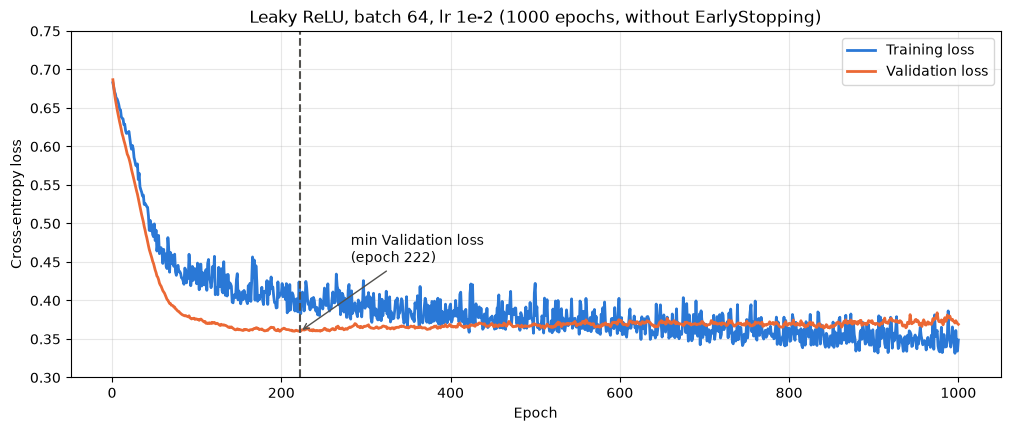

Epoch  100: Training loss 0.4217, Validation loss 0.3761, Validation accuracy 0.8652
Epoch  222: Training loss 0.3919, Validation loss 0.3597, Validation accuracy 0.8764
Epoch  400: Training loss 0.3953, Validation loss 0.3680, Validation accuracy 0.8483
Epoch 1000: Training loss 0.3486, Validation loss 0.3691, Validation accuracy 0.8596


In [14]:
best_history = grid_histories[("leaky_relu", 64, 1e-2)]
best_epoch_full = best_history["epoch"][int(np.argmin(best_history["validation_loss"]))]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(best_history["epoch"], best_history["training_loss"], color=COLOR_TRAIN, linewidth=2, label="Training loss")
ax.plot(best_history["epoch"], best_history["validation_loss"], color=COLOR_VALID, linewidth=2, label="Validation loss")
ax.axvline(best_epoch_full, color="#52514e", linestyle="--", linewidth=1.5)
ax.annotate(f"min Validation loss\n(epoch {best_epoch_full})", xy=(best_epoch_full, min(best_history["validation_loss"])),
            xytext=(best_epoch_full + 60, 0.45), color="#0b0b0b",
            arrowprops=dict(arrowstyle="->", color="#52514e"))
ax.set_title("Leaky ReLU, batch 64, lr 1e-2 (1000 epochs, without EarlyStopping)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_ylim(0.3, 0.75)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

for epoch in [100, best_epoch_full, 400, 1000]:
    i = epoch - 1
    print(f"Epoch {epoch:4d}: Training loss {best_history['training_loss'][i]:.4f}, "
          f"Validation loss {best_history['validation_loss'][i]:.4f}, "
          f"Validation accuracy {best_history['validation_accuracy'][i]:.4f}")

In [15]:
def simulate_early_stopping(validation_losses, patience, delta=0.00001):
    #EarlyStopping.check_and_save()와 같은 규칙으로 멈추는 에폭과 저장되는 에폭 계산
    val_loss_min, counter, best_epoch = None, 0, None
    for epoch, loss in enumerate(validation_losses, start=1):
        if val_loss_min is None:
            val_loss_min, best_epoch = loss, epoch
        elif loss < val_loss_min - delta:
            val_loss_min, best_epoch, counter = loss, epoch, 0
        else:
            counter += 1
            if counter >= patience:
                return epoch, best_epoch, val_loss_min
    return len(validation_losses), best_epoch, val_loss_min

rows = []
for patience in [5, 10, 20, 30, 50, 100]:
    stop_epoch, saved_epoch, saved_loss = simulate_early_stopping(best_history["validation_loss"], patience)
    rows.append({"patience": patience, "stop_epoch": stop_epoch, "saved_model_epoch": saved_epoch,
                 "saved_validation_loss": round(saved_loss, 4),
                 "saved_validation_accuracy": round(best_history["validation_accuracy"][saved_epoch - 1], 4)})
display(pd.DataFrame(rows))

,patience,stop_epoch,saved_model_epoch,saved_validation_loss,saved_validation_accuracy
0,5,119,114,0.3701,0.8708
1,10,172,162,0.3608,0.8764
2,20,218,198,0.3600,0.8764
3,30,252,222,0.3597,0.8764
4,50,272,222,0.3597,0.8764
5,100,322,222,0.3597,0.8764


In [16]:
final_model, final_history, test_data_loader = run_experiment(
    activation="leaky_relu", batch_size=64, learning_rate=1e-2,
    wandb_mode="online", group="final",
    early_stop=True, early_stop_patience=50, early_stop_delta=0.00001
)

wandb: setting up run 3tmax6bv
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\University\Grade_3\3-2\DeepLearningClass\git\link_dl\_03_homeworks\homework_2\wandb\run-20261016_021752-3tmax6bv
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run 2026-10-16_02-17-51
wandb:  View project at https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic
wandb:  View run at https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic/runs/3tmax6bv


{'epochs': 1000, 'batch_size': 64, 'learning_rate': 0.01, 'activation': 'leaky_relu', 'n_hidden_unit_list': [20, 20], 'seed': 42, 'early_stop': True, 'early_stop_patience': 50, 'early_stop_delta': 1e-05}
Epoch 100, Training loss 0.4217, Validation loss 0.3761, Validation accuracy 0.8652
Epoch 200, Training loss 0.4089, Validation loss 0.3618, Validation accuracy 0.8820


wandb: updating run metadata


Epoch 272, Early stopping counter: 50 out of 50 *** TRAIN EARLY STOPPED! ***
→ best epoch: 222, best validation loss: 0.3597
Loaded best checkpoint: titanic_checkpoint_2026-10-16_02-17-51.pt


wandb: uploading wandb-metadata.json; uploading requirements.txt; updating run metadata
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 0-271, summary
wandb: 
wandb: Run history:
wandb:               Epoch ▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇█
wandb:       Training loss ██▇▆▆▆▆▆▄▃▂▂▂▂▂▂▂▂▂▂▁▂▂▂▁▂▂▁▁▁▁▂▁▂▁▁▁▁▁▁
wandb: Validation accuracy ▁▄▃▄▄▅▆▆▆▇▇▇███▇▇▇█▇█████████████▇█████▇
wandb:     Validation loss █▇▆▅▅▄▄▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:               Best epoch 222
wandb: Best validation accuracy 0.8764
wandb:                    Epoch 272
wandb:            Training loss 0.40939
wandb: 
wandb:  View run 2026-10-16_02-17-51 at: https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic/runs/3tmax6bv
wandb:  View project at: https://wandb.ai/seoi180011-korea-university-of-technology-and-education/titanic
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other f

In [17]:
#불러온 모델이 진짜 최적 에폭의 모델인지 검증 데이터로 다시 확인
final_model.eval()
loss_fn = nn.CrossEntropyLoss()
with torch.no_grad():
    validation_batch = next(iter(DataLoader(validation_dataset, batch_size=len(validation_dataset))))
    output = final_model(validation_batch['input'])
    reloaded_loss = loss_fn(output, validation_batch['target']).item()
    reloaded_accuracy = (output.argmax(dim=1) == validation_batch['target']).float().mean().item()

print(f"학습 중단 epoch: {final_history['epoch'][-1]}")
print(f"불러온 모델의 Validation loss {reloaded_loss:.4f}, Validation accuracy {reloaded_accuracy:.4f}")

학습 중단 epoch: 272
불러온 모델의 Validation loss 0.3597, Validation accuracy 0.8764


In [18]:
def make_submission(model, test_data_loader, submission_file_path):
    #PassengerId는 모델 입력에서 뺐으므로 제출 파일 만들 때만 test.csv에서 다시 읽어서 사용
    test_df = pd.read_csv(os.path.join(CURRENT_FILE_PATH, "test.csv"))

    model.eval()
    predictions = []
    with torch.no_grad():
        for test_batch in test_data_loader:
            output_test = model(test_batch['input'])
            predictions.append(output_test.argmax(dim=1)) #출력값이 큰 클래스 선택 / 0 : 사망, 1 : 생존
    predictions = torch.cat(predictions)

    assert len(predictions) == len(test_df)
    submission_df = pd.DataFrame({
        "PassengerId": test_df["PassengerId"],
        "Survived": predictions.numpy(),
    })
    submission_df.to_csv(submission_file_path, index=False)
    print(f"Submission saved: {os.path.basename(submission_file_path)} "
          f"(survived: {submission_df['Survived'].sum()} / {len(submission_df)})")

    return submission_df


submission_df = make_submission(final_model, test_data_loader, os.path.join(CURRENT_FILE_PATH, "submission.csv"))
display(submission_df.head(10))

Submission saved: submission.csv (survived: 157 / 418)


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [19]:
#예측 결과가 상식적인지 확인 / 성별, 객실 등급별 예측 생존율
check_df = test_df.merge(submission_df, on="PassengerId")
print("[성별 예측 생존율]")
print(check_df.groupby("Sex")["Survived"].mean().round(3).to_string())
print("\n[객실 등급별 예측 생존율]")
print(check_df.groupby("Pclass")["Survived"].mean().round(3).to_string())

[성별 예측 생존율]
Sex
female    0.908
male      0.071

[객실 등급별 예측 생존율]
Pclass
1    0.514
2    0.344
3    0.321


### 요구사항 3 고찰

EarlyStopping으로 검증 손실이 가장 낮았던 222 에폭의 모델을 최종 모델로 사용함. 222 에폭 이후에는 학습 손실은 계속 줄지만 검증 손실은 다시 올라가는 과적합이 나타나서, 1000 에폭까지 학습한 모델로 테스트하면 검증 손실 0.3691, 정확도 0.8596으로 성능이 더 나빠짐. 테스트 데이터에는 정답이 없으므로 검증 손실이 가장 낮은 시점의 모델로 테스트해야 함. 학습이 멈춘 272 에폭의 모델도 이미 50 에폭 동안 나아지지 않은 모델이라, EarlyStopping이 저장해 둔 222 에폭 모델을 불러와서 submission.csv를 만듦. patience는 검증 손실이 흔들리는 정도를 고려해서 정해야 하는데, 5 ~ 20처럼 작게 주면 잠깐 정체된 구간에서 너무 일찍 멈춰서 50으로 정함. 예측 결과도 여성과 1등석의 생존율이 높게 나와서 실제 타이타닉 상황과 비슷한 경향을 학습한 것을 확인함.

### [요구사항 4] 

- Public Score: 0.77751
- Leaderboard 순위: 4500위

![Kaggle Leaderboard](https://i.imgur.com/r1nXLLy.png)

### 요구사항 4 고찰

검증 정확도는 0.8764였는데 Kaggle 점수는 0.7775로 약 10%p 낮게 나왔음. 검증 데이터가 178명뿐이라 1명만 달라도 정확도가 약 0.56%p씩 바뀌어서 우연의 영향을 많이 받음. 또 36개 조합과 EarlyStopping 시점을 모두 검증 손실 기준으로 골랐기 때문에, 선택된 모델이 이 검증 데이터에 유리하게 맞춰져 있어 검증 성능이 실제보다 좋게 나왔을 수 있음. 다음에는 교차검증이나 여러 시드로 반복 실험해서 더 안정적으로 하이퍼파라미터를 고르면 차이를 줄일 수 있을 것 같음.

### 종합 고찰

회귀 모델을 분류 모델로 바꾸면서 출력층을 클래스 수만큼 두고 CrossEntropyLoss를 쓰고 예측할 때는 출력값이 가장 큰 클래스를 고른다는 걸 직접 구현해 봤습니다. 또 표준화할 때 평균, 표준편차를 학습 데이터에서만 계산해야 검증, 테스트 데이터 정보가 학습에 섞이지 않는다는 것도 알게 됐습니다. 

시드를 고정하니 같은 설정의 실험이 매번 똑같은 결과를 내서 하이퍼파라미터를 공정하게 비교하려면 다른 조건을 모두 고정해야 한다는 걸 확인했습니다. 그리고 하이퍼파라미터끼리 서로 영향을 주기 때문에 하나씩 따로 고르면 최적 조합을 놓칠 수 있다는 걸 깨달았습니다. 

학습률이 클수록 최저점에 빨리 도달하지만 그만큼 과적합도 빨리 온다는 것을 이번 과제를 통해서 직관적으로 알 수 있게 됐습니다.

### 숙제 후기

이번 과제에서 처음으로 Kaggle 대회에 직접 제출해 보았습니다. Kaggle을 알고 있었긴 했지만 이런 대회는 처음 나가보는 것이라 좀 신기했던 것 같습니다. 그런데 점수가 77%대로 나와서 아쉬웠습니다. 

숙제를 할 때, 하이퍼파라미터들을 비교하면서 학습률에 따라 Sigmoid가 아예 학습이 안 되기도 하고 잘 되기도 하는 것을 봤습니다. 하이퍼파라미터는 따로따로가 아니라 같이 봐야 한다는 것을 느꼈습니다. EarlyStopping이나 과적합처럼 수업에서 배운 개념을 직접 그래프로 확인하면서 좀 더 직관적으로 이해할 수 있었습니다.